# 278. Does H/P give more evidence per aligned position than BLOSUM62?

No kmerseek in this notebook.
[Notebook 273](https://github.com/seanome/2024-kmerseek-analysis/blob/olgabot/hp-agreement-per-100/notebooks/273_hp_agreement_per_100_positions_pfam_seed_scope40.ipynb)
found that in Pfam seed pairs under 20% identity, H/P gives 1.13 times the evidence per
aligned position of the 20 amino acids. There the 20 amino acids were scored by identity
only: a position counts if the two residues are the same, and nothing otherwise. No aligner
scores that way. BLAST and HMMer give partial credit to similar residues, using a substitution
matrix such as BLOSUM62. This notebook asks whether H/P still gives more evidence per aligned
position when the 20 amino acids are scored with BLOSUM62.

**Data.** The aligned pairs notebook 273 reads, with the same filters:

* Pfam-A 38.2 seed alignments (`~/data/pfam/230_pfam_seed_pair_alignments.parquet`, built by
  `scripts/pfam_seed_pair_alignments.py`). Pairs with at least 50 aligned positions.
* SCOPe 2.08, 40% identity set, aligned by structure with USalign
  (`~/data/scope/230_scope40_pair_alignments.parquet`, built by
  `scripts/scope_pair_structural_alignments.py`). Pairs with at least 50 aligned positions and
  TM-score at least 0.5 on one of the two domains.

An aligned position is a column where neither sequence has a gap.

**Six ways to score an aligned position**, in bits:

| scoring | alphabet | how a position is scored |
|---|---|---|
| identity | 20 amino acids | 1 if the two residues are the same, else 0 (notebook 273's 20 amino acid count) |
| H/P agreement | `hp_thomas_dill2` | 1 if both are H or both are P, else 0 (notebook 273's H/P count) |
| BLOSUM62 | 20 amino acids | BLOSUM62 score, in bits |
| H/P from BLOSUM62 | `hp_thomas_dill2` | BLOSUM62's own pair frequencies summed into H and P, as log-odds in bits |
| BLOSUM45 | 20 amino acids | BLOSUM45 score, in bits (BLOSUM45 is built for more distant pairs) |
| H/P from BLOSUM45 | `hp_thomas_dill2` | the same, from BLOSUM45 |

H is `ACFILMVWY` and P is `DEGHKNPQRST`. A BLOSUM score s is turned into bits as
$\lambda s = \log_2 \frac{p_{ab}}{q_a q_b}$, where $q$ is the residue background and $\lambda$ is
the one number that makes the implied pair frequencies $p_{ab} = q_a q_b 2^{\lambda s_{ab}}$
sum to 1. The background is the residue composition of all aligned positions in the Pfam seed
pairs. "H/P from BLOSUM62" sums $p_{ab}$ over the residues in each class, so it is the H/P
scoring that BLOSUM62 itself implies. It is not fitted to these pairs.

**How far a pair is from chance: bits per aligned position.** For each pair and each scoring,
the mean score over its aligned positions is compared with chance: each query residue paired
with a residue drawn from the target's own aligned composition. The measure is how fast the
chance of an unrelated pair scoring as well falls as aligned positions are added:

$$\Pr(\text{chance pair reaches the same mean score over } n \text{ positions}) \approx 2^{-n \cdot \text{bits per position}}$$

(Cramér's theorem: bits per position $= \sup_{\theta \ge 0} \theta m - \log_2 \sum_k w_k 2^{\theta v_k}$,
where $m$ is the pair's mean score and $w_k$ the chance probability of score $v_k$.) For
agree/disagree scoring it is exactly notebook 273's $I$, so the identity and H/P agreement rows
reproduce notebook 273. A pair needs about $20/\text{bits}$ aligned positions to reach
$2^{-20}$, about one in a million. Higher is better. It puts the six scorings on one scale,
whatever the units of their scores.

A second measure, z per position, is printed beside it:
(mean score − chance mean) / chance standard deviation per position. It assumes chance scores
are spread like a bell curve, which is far off when chance agreement is small (6.5% for
identity), so it is not used for the decision. The first draft of this notebook used z, and z
ranked identity above H/P agreement under 20% identity, the opposite of notebook 273. That is
why the decision moved to bits; the BLOSUM62 comparison came out the same way under both.

**Grouping.** Mainly by SCOPe's relationship between the two domains, which does not use
identity. Pfam pairs are also shown by identity bin, with notebook 273's caveat: identity is
the 20 amino acid agreement, so binning by it holds the 20 amino acid scores down in the low
bins.

**Decision rule.** Written after a pilot on the same data (the pilot showed BLOSUM62 ahead in
every group), so it is not a blind test. H/P beats BLOSUM62 if H/P agreement or H/P from
BLOSUM62 has higher mean bits per aligned position than BLOSUM62, with the 95% interval of the
difference above zero, in SCOPe same family, same superfamily (different family), or same fold
(different superfamily) pairs, over all identities. Intervals resample whole query domains
(SCOPe) or whole families (Pfam), because pairs that share a domain or a family are not
independent.

**What this decides.** If H/P beats BLOSUM62 anywhere, notebook 273's 1.13 can lead to a
headline, and the next test is divergence time. If not, the 1.13 holds only against
identity scoring, which no aligner uses, and the case for H/P cannot rest on evidence per
aligned position.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

sys.path.insert(0, str(Path.cwd()))
import hp_conservation_utils as hc

pl.Config.set_tbl_rows(80)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(220)

FIG = Path("../figures")
PFAM_ALN = Path("/Users/olga/data/pfam/230_pfam_seed_pair_alignments.parquet")
SCOPE_ALN = Path("/Users/olga/data/scope/230_scope40_pair_alignments.parquet")
PFAM_OUT = Path("/Users/olga/data/pfam/278_pfam_seed_pair_scores.parquet")
SCOPE_OUT = Path("/Users/olga/data/scope/278_scope40_pair_scores.parquet")
MIN_COLS = 50  # same filter as notebooks 230 and 273
MIN_TM = 0.5  # SCOPe only, same as notebooks 230 and 273
N_BOOT = 1000
SEED = 277  # from when this was notebook 277 (renumbered: PR 107 also took 277); kept so intervals do not move
HP = "hp_thomas_dill2"

pfam_aln = pl.read_parquet(PFAM_ALN)
scope_aln = pl.read_parquet(SCOPE_ALN).filter(
    pl.max_horizontal("tm_q", "tm_t") >= MIN_TM
)

# Background: residue composition of every aligned position in the Pfam seed pairs, both sides.
counts = np.zeros(20)
for qa, ta in pfam_aln.select("qaln", "taln").iter_rows():
    q, t = hc.aligned_codes(qa, ta)
    counts += np.bincount(q, minlength=20)[:20] + np.bincount(t, minlength=20)[:20]
background = counts / counts.sum()

b62, p62, lam62 = hc.substitution_bits("BLOSUM62", background)
b45, p45, lam45 = hc.substitution_bits("BLOSUM45", background)
SCHEMES = {
    "identity": hc.agreement_bits("protein20"),
    "H/P agreement": hc.agreement_bits(HP),
    "BLOSUM62": b62,
    "H/P from BLOSUM62": hc.class_bits(p62, background, HP),
    "BLOSUM45": b45,
    "H/P from BLOSUM45": hc.class_bits(p45, background, HP),
}
SCHEME_ORDER = list(SCHEMES)
ALPHABET_OF = {
    "identity": "20 amino acids",
    "H/P agreement": "H/P",
    "BLOSUM62": "20 amino acids",
    "H/P from BLOSUM62": "H/P",
    "BLOSUM45": "20 amino acids",
    "H/P from BLOSUM45": "H/P",
}


def load_or_compute(df, out_path, keys):
    # One row per (pair, scoring); cached to out_path.
    if out_path.exists():
        return pl.read_parquet(out_path)
    t = hc.score_pairs(df["qaln"].to_list(), df["taln"].to_list(), SCHEMES, MIN_COLS)
    t = t.join(
        df.select(keys)
        .with_row_index("row")
        .with_columns(pl.col("row").cast(pl.Int64)),
        on="row",
    ).drop("row")
    t.write_parquet(out_path)
    return t


pfam = hc.add_identity_bin(
    load_or_compute(
        pfam_aln, PFAM_OUT, ["family", "family_id", "query", "target", "seqid_ali"]
    )
)
scope = hc.add_identity_bin(
    load_or_compute(scope_aln, SCOPE_OUT, ["query", "target", "category", "seqid_ali"])
)
CAT_ORDER = [
    "same_family",
    "same_superfamily_diff_family",
    "same_fold_diff_superfamily",
    "diff_fold_same_class",
]
CAT_LABEL = {
    "same_family": "same family",
    "same_superfamily_diff_family": "same superfamily,\ndifferent family",
    "same_fold_diff_superfamily": "same fold,\ndifferent superfamily",
    "diff_fold_same_class": "different fold,\nsame class",
}
scope = scope.with_columns(pl.col("category").cast(pl.Enum(CAT_ORDER)))
print(
    f"Pfam: {pfam.filter(pl.col('scheme') == 'identity').height:_} pairs from "
    f"{pfam['family'].n_unique():_} families; SCOPe: {scope.filter(pl.col('scheme') == 'identity').height:_} pairs "
    f"(at least {MIN_COLS} aligned positions; SCOPe TM-score >= {MIN_TM} on one domain)"
)
print(f"Background from {int(counts.sum()):_} aligned residues")

Pfam: 148_482 pairs from 26_645 families; SCOPe: 24_505 pairs (at least 50 aligned positions; SCOPe TM-score >= 0.5 on one domain)
Background from 49_021_486 aligned residues


## 1. The scorings themselves

For each scoring, the table gives $\lambda$ (bits per BLOSUM score unit) and the scoring's own
relative entropy: the mean bits per aligned position that a pair gets when it is exactly as
diverged as the pairs the matrix was built from. This is an expectation under that model; individual pairs can score higher or lower. The H/P scorings from BLOSUM have less, as they must: summing
pair frequencies into two classes can only lose information. The question in sections 2 and 3
is whether real distant pairs follow BLOSUM62's pair frequencies closely enough for that to
hold on them too.

The figure shows the 2 x 2 H/P log-odds that BLOSUM62 and BLOSUM45 imply. Positive is a pair
of classes seen in homologs more often than by chance.

Background, % of aligned residues:
A 7.8  C 1.5  D 5.5  E 6.6  F 4.3  G 6.2  H 2.2  I 5.8  K 5.6  L 10.3  M 2.1  N 4.2  P 4.4  Q 4.0  R 5.6  S 6.9  T 5.4  V 6.7  W 1.4  Y 3.4
shape: (2, 7)
┌──────────┬──────────────────────────────┬────────────────────────────────┬─────────────────────────────────┬───────┬───────┬────────┐
│ matrix   ┆ lambda (bits per score unit) ┆ relative entropy, 20 aa (bits) ┆ relative entropy, H/P from it … ┆ H-H   ┆ P-P   ┆ H-P    │
│ ---      ┆ ---                          ┆ ---                            ┆ ---                             ┆ ---   ┆ ---   ┆ ---    │
│ str      ┆ f64                          ┆ f64                            ┆ f64                             ┆ f64   ┆ f64   ┆ f64    │
╞══════════╪══════════════════════════════╪════════════════════════════════╪═════════════════════════════════╪═══════╪═══════╪════════╡
│ BLOSUM62 ┆ 0.4595                       ┆ 0.57                           ┆ 0.159                           ┆ 0.652 ┆ 0.461 ┆ -0.9

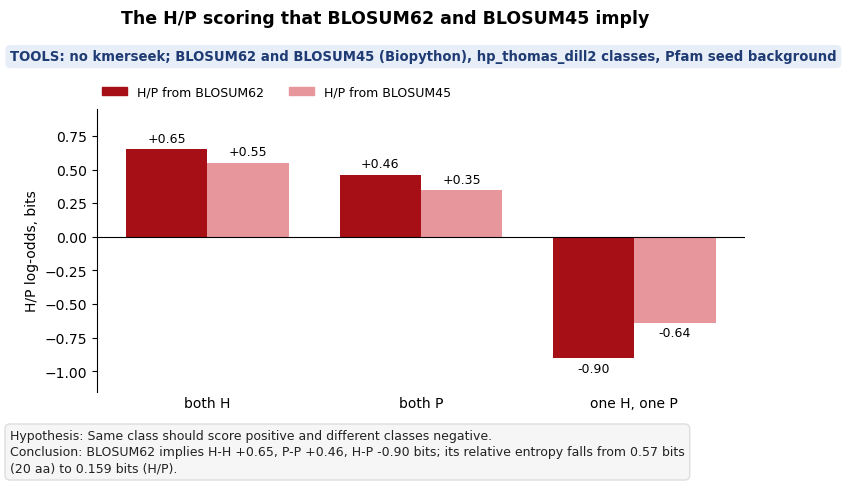

In [2]:
cls = hc.TABLES[HP][np.frombuffer(hc.PROTEIN20_ORDER.encode(), dtype=np.uint8)]
i_h, i_p = int(np.flatnonzero(cls == 0)[0]), int(np.flatnonzero(cls == 1)[0])
rows = []
for name, lam, p in [("BLOSUM62", lam62, p62), ("BLOSUM45", lam45, p45)]:
    s20 = SCHEMES[name]
    shp = SCHEMES[f"H/P from {name}"]
    rows.append(
        {
            "matrix": name,
            "lambda (bits per score unit)": round(lam, 4),
            "relative entropy, 20 aa (bits)": round(float((p * s20).sum()), 3),
            "relative entropy, H/P from it (bits)": round(float((p * shp).sum()), 3),
            "H-H": round(float(shp[i_h, i_h]), 3),
            "P-P": round(float(shp[i_p, i_p]), 3),
            "H-P": round(float(shp[i_h, i_p]), 3),
        }
    )
mat_tab = pl.DataFrame(rows)
print("Background, % of aligned residues:")
print("  ".join(f"{a} {100 * f:.1f}" for a, f in zip(hc.PROTEIN20_ORDER, background)))
print(mat_tab)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
pairs = ["H-H", "P-P", "H-P"]
MATRIX_COLOR = {
    "BLOSUM62": "#a50f15",
    "BLOSUM45": "#e7969c",
}  # used only in this figure
xx = np.arange(len(pairs))
for j, r in enumerate(rows):
    vals = [r[k] for k in pairs]
    ax.bar(xx + (j - 0.5) * 0.38, vals, width=0.38, color=MATRIX_COLOR[r["matrix"]])
    for xi, v in zip(xx, vals):
        ax.text(
            xi + (j - 0.5) * 0.38,
            v + (0.03 if v > 0 else -0.03),
            f"{v:+.2f}",
            ha="center",
            va="bottom" if v > 0 else "top",
            fontsize=9,
        )
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xx, ["both H", "both P", "one H, one P"])
ax.set_ylabel("H/P log-odds, bits")
ax.set_ylim(-1.15, 0.95)
for side in ("top", "right", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(axis="x", length=0)
ax.legend(
    handles=[
        Patch(color=MATRIX_COLOR[r["matrix"]], label=f"H/P from {r['matrix']}")
        for r in rows
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
)
hc.finish_figure(
    fig,
    FIG / "278_hp_log_odds_implied_by_blosum62_and_blosum45.png",
    tools=f"no kmerseek; BLOSUM62 and BLOSUM45 (Biopython), {HP} classes, Pfam seed background",
    title="The H/P scoring that BLOSUM62 and BLOSUM45 imply",
    hypothesis="Same class should score positive and different classes negative.",
    conclusion=(
        f"BLOSUM62 implies H-H {rows[0]['H-H']:+.2f}, P-P {rows[0]['P-P']:+.2f}, H-P {rows[0]['H-P']:+.2f} bits; "
        f"its relative entropy falls from {rows[0]['relative entropy, 20 aa (bits)']} bits (20 aa) to "
        f"{rows[0]['relative entropy, H/P from it (bits)']} bits (H/P)."
    ),
    wrap=110,
)

## 2. SCOPe pairs by relationship: bits per aligned position for each scoring

Mean bits per aligned position over the pairs in each SCOPe category, with a 95% interval from
resampling query domains. Left: all identities. Right: only the pairs under 20% identity.
Grey marks are the 20 amino acids, red marks H/P. Filled marks are substitution scorings
(BLOSUM62 and the H/P scoring it implies); open marks are agreement only (identity, and H/P
agreement, as in notebook 273). The top row is bits per aligned position; the bottom row is
each scoring as a fraction of BLOSUM62 (the dashed line at 1), so the distant pairs, where
all values are small, can be read. BLOSUM45 and its H/P scoring are in the printed table, not
the figure.
Higher is better. The table also gives the aligned positions a pair at that mean needs for a
one-in-a-million chance of an unrelated pair doing as well, $20/\text{bits}$, and the mean z per
position.

SCOPe, all identities: mean per pair, 95% interval resampling query domains
shape: (24, 9)
┌──────────────────────────────┬───────────────────┬───────┬────────────┬───────────────────┬────────┬────────┬──────────────────────────────┬────────────────┐
│ category                     ┆ scheme            ┆ pairs ┆ mean score ┆ bits per position ┆ 95% lo ┆ 95% hi ┆ positions for 1 in a million ┆ z per position │
│ ---                          ┆ ---               ┆ ---   ┆ ---        ┆ ---               ┆ ---    ┆ ---    ┆ ---                          ┆ ---            │
│ enum                         ┆ enum              ┆ i64   ┆ f64        ┆ f64               ┆ f64    ┆ f64    ┆ i64                          ┆ f64            │
╞══════════════════════════════╪═══════════════════╪═══════╪════════════╪═══════════════════╪════════╪════════╪══════════════════════════════╪════════════════╡
│ same_family                  ┆ identity          ┆ 11117 ┆ 0.212      ┆ 0.2053            ┆ 0.2009 ┆ 0.2097


Decision rule test, SCOPe all identities: H/P scorings minus BLOSUM45
shape: (8, 7)
┌──────────────────────────────┬─────────────────────────────────┬───────┬─────────────────────────────────┬─────────┬─────────┬───────────┐
│ category                     ┆ comparison                      ┆ pairs ┆ mean difference, bits_per_posi… ┆ 95% lo  ┆ 95% hi  ┆ H/P ahead │
│ ---                          ┆ ---                             ┆ ---   ┆ ---                             ┆ ---     ┆ ---     ┆ ---       │
│ enum                         ┆ str                             ┆ i64   ┆ f64                             ┆ f64     ┆ f64     ┆ bool      │
╞══════════════════════════════╪═════════════════════════════════╪═══════╪═════════════════════════════════╪═════════╪═════════╪═══════════╡
│ same_family                  ┆ H/P agreement minus BLOSUM45    ┆ 11117 ┆ -0.1843                         ┆ -0.1884 ┆ -0.18   ┆ false     │
│ same_family                  ┆ H/P from BLOSUM45 minus BLOSUM… ┆ 11

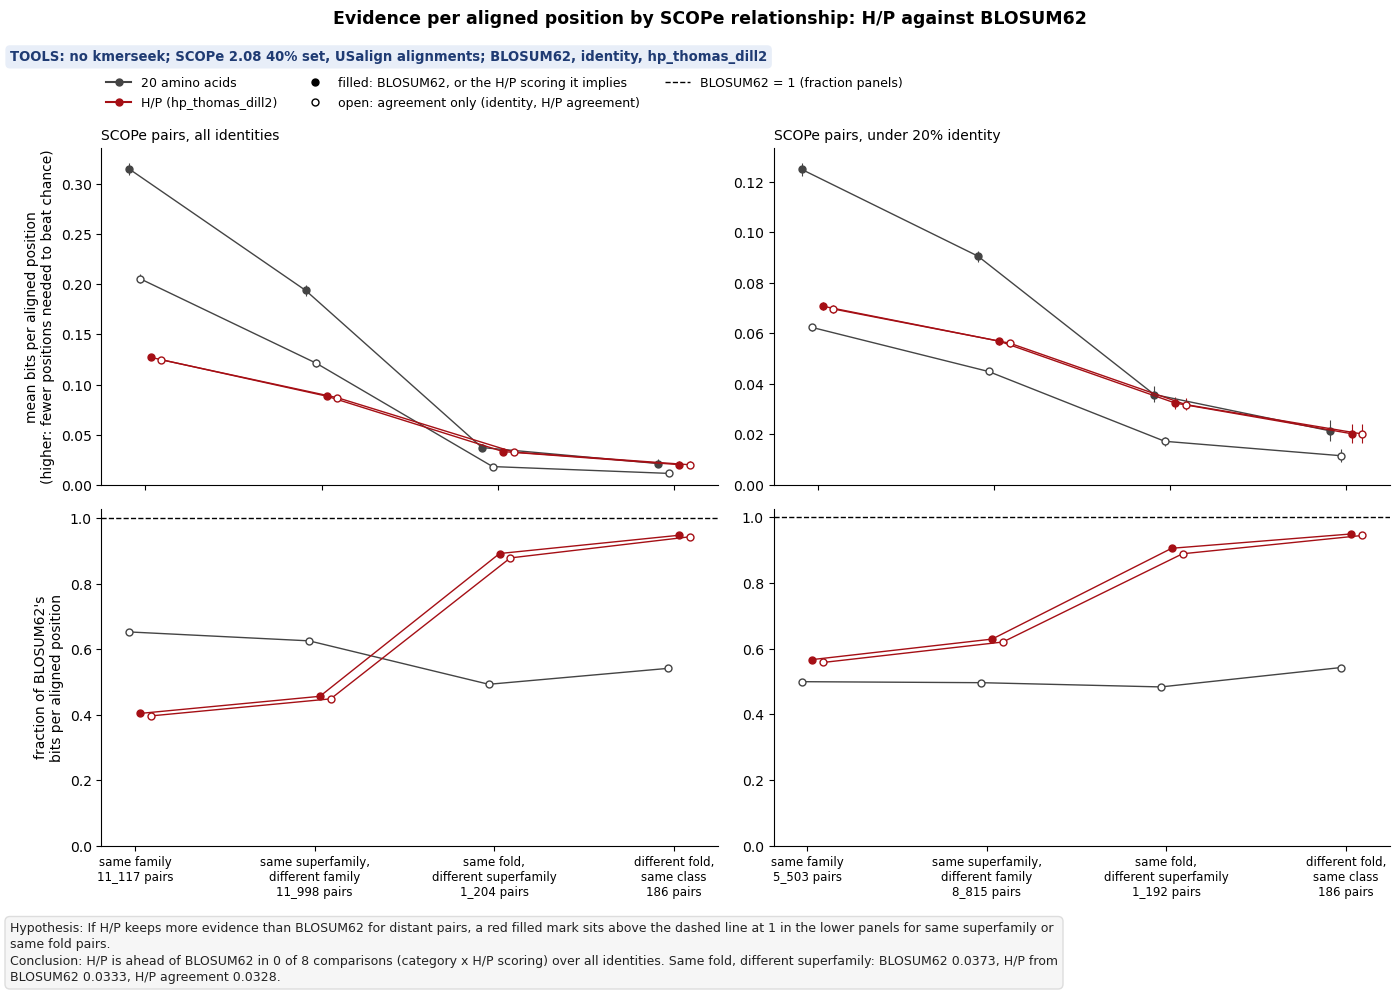

In [3]:
ENUMS = {"category": CAT_ORDER, "identity_bin": hc.IDENTITY_LABELS}


def with_order(df, by):
    return df.with_columns(
        pl.col("scheme").cast(pl.Enum(SCHEME_ORDER)),
        *[pl.col(c).cast(pl.Enum(ENUMS[c])) for c in by],
    ).sort(by + ["scheme"])


def summarise(df, by, cluster):
    rows = []
    for key, g in df.group_by(by + ["scheme"]):
        m, lo, hi = hc.cluster_bootstrap_mean_ci(
            g["bits_per_position"], g[cluster], N_BOOT, SEED
        )
        rows.append(
            dict(zip(by + ["scheme"], key))
            | {
                "pairs": g.height,
                "mean score": round(float(g["score"].mean()), 3),
                "bits per position": round(m, 4),
                "95% lo": round(lo, 4),
                "95% hi": round(hi, 4),
                "positions for 1 in a million": round(20 / m) if m > 0 else None,
                "z per position": round(float(g["z_per_position"].mean()), 3),
            }
        )
    return with_order(pl.DataFrame(rows), by)


def differences(df, by, cluster, against="BLOSUM62", metric="bits_per_position"):
    # Per pair: H/P scoring minus BLOSUM, then the mean with a cluster-resampled interval.
    wide = df.pivot(
        on="scheme",
        index=["query", "target"]
        + [c for c in by + [cluster] if c not in ("query", "target")],
        values=metric,
    )
    rows = []
    for key, g in wide.group_by(by):
        for hp_name in ["H/P agreement", f"H/P from {against}"]:
            m, lo, hi = hc.cluster_bootstrap_mean_ci(
                g[hp_name] - g[against], g[cluster], N_BOOT, SEED
            )
            rows.append(
                dict(zip(by, key))
                | {
                    "comparison": f"{hp_name} minus {against}",
                    "pairs": g.height,
                    f"mean difference, {metric}": round(m, 4),
                    "95% lo": round(lo, 4),
                    "95% hi": round(hi, 4),
                    "H/P ahead": lo > 0,
                }
            )
    return (
        pl.DataFrame(rows)
        .with_columns(*[pl.col(c).cast(pl.Enum(ENUMS[c])) for c in by])
        .sort(by + ["comparison"])
    )


scope_lo = scope.filter(pl.col("identity_bin") == "<20%")
sc_all = summarise(scope, ["category"], "query")
sc_lo = summarise(scope_lo, ["category"], "query")
print("SCOPe, all identities: mean per pair, 95% interval resampling query domains")
print(sc_all)
print("\nSCOPe, pairs under 20% identity only")
print(sc_lo)
diff_tabs = {}
for against in ["BLOSUM62", "BLOSUM45"]:
    d_all = differences(scope, ["category"], "query", against)
    d_lo = differences(scope_lo, ["category"], "query", against)
    diff_tabs[against] = d_all
    print(f"\nDecision rule test, SCOPe all identities: H/P scorings minus {against}")
    print(d_all)
    print(f"Same, pairs under 20% identity only (not part of the rule)")
    print(d_lo)
d_z = differences(scope, ["category"], "query", "BLOSUM62", "z_per_position")
print(
    "\nThe same test on z per position (not used for the decision): H/P scorings minus BLOSUM62, all identities"
)
print(d_z)

SHOWN = ["BLOSUM62", "identity", "H/P from BLOSUM62", "H/P agreement"]
COLOR = {"20 amino acids": "#444444", "H/P": "#a50f15"}  # notebook 230/273 colours
FILLED = {
    "BLOSUM62": True,
    "H/P from BLOSUM62": True,
    "identity": False,
    "H/P agreement": False,
}
OFFSET = {
    "BLOSUM62": -0.09,
    "identity": -0.03,
    "H/P from BLOSUM62": 0.03,
    "H/P agreement": 0.09,
}


def plot_scorings(ax, tab, key, ratio=False):
    # One line per scoring across ordered groups: colour = alphabet, filled or open = scoring.
    b62 = (
        tab.filter(pl.col("scheme") == "BLOSUM62")
        .sort(key)["bits per position"]
        .to_numpy()
    )
    x = np.arange(b62.size)
    if ratio:
        ax.axhline(1, color="black", ls="--", lw=1)
    for name in SHOWN:
        if ratio and name == "BLOSUM62":
            continue
        t = tab.filter(pl.col("scheme") == name).sort(key)
        m = t["bits per position"].to_numpy()
        col = COLOR[ALPHABET_OF[name]]
        style = dict(
            color=col,
            lw=1,
            marker="o",
            ms=5,
            mec=col,
            mfc=col if FILLED[name] else "white",
        )
        if ratio:
            ax.plot(x + OFFSET[name], m / b62, **style)
        else:
            err = np.vstack([m - t["95% lo"].to_numpy(), t["95% hi"].to_numpy() - m])
            ax.errorbar(
                x + OFFSET[name], m, yerr=err, elinewidth=0.8, capsize=0, **style
            )
    ax.set_ylim(bottom=0)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


handles = [
    Line2D(
        [], [], color=COLOR["20 amino acids"], marker="o", ms=5, label="20 amino acids"
    ),
    Line2D([], [], color=COLOR["H/P"], marker="o", ms=5, label=f"H/P ({HP})"),
    Line2D(
        [],
        [],
        ls="",
        marker="o",
        ms=5,
        color="black",
        label="filled: BLOSUM62, or the H/P scoring it implies",
    ),
    Line2D(
        [],
        [],
        ls="",
        marker="o",
        ms=5,
        color="black",
        mfc="white",
        label="open: agreement only (identity, H/P agreement)",
    ),
    Line2D(
        [], [], color="black", ls="--", lw=1, label="BLOSUM62 = 1 (fraction panels)"
    ),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for col_i, (tab, used) in enumerate(
    [(sc_all, "all identities"), (sc_lo, "under 20% identity")]
):
    plot_scorings(axes[0, col_i], tab, "category")
    plot_scorings(axes[1, col_i], tab, "category", ratio=True)
    axes[0, col_i].set_title(f"SCOPe pairs, {used}", loc="left", fontsize=10)
    npairs = (
        tab.filter(pl.col("scheme") == "BLOSUM62").sort("category")["pairs"].to_list()
    )
    axes[1, col_i].set_xticks(
        range(len(CAT_ORDER)),
        [f"{CAT_LABEL[c]}\n{n:_} pairs" for c, n in zip(CAT_ORDER, npairs)],
        fontsize=8.5,
    )
    axes[0, col_i].set_xticks(range(len(CAT_ORDER)), [""] * len(CAT_ORDER))
axes[0, 0].set_ylabel(
    "mean bits per aligned position\n(higher: fewer positions needed to beat chance)"
)
axes[1, 0].set_ylabel("fraction of BLOSUM62's\nbits per aligned position")
# kept out of tight_layout so it does not widen the left column; the header goes above it
axes[0, 0].legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.1),
    ncol=3,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
).set_in_layout(False)
d62 = diff_tabs["BLOSUM62"]
n_ahead = int(d62["H/P ahead"].sum())
sfd = sc_all.filter(pl.col("category") == "same_fold_diff_superfamily")
z_b = sfd.filter(pl.col("scheme") == "BLOSUM62")["bits per position"][0]
z_h = sfd.filter(pl.col("scheme") == "H/P from BLOSUM62")["bits per position"][0]
z_a = sfd.filter(pl.col("scheme") == "H/P agreement")["bits per position"][0]
hc.finish_figure(
    fig,
    FIG / "278_bits_per_position_hp_vs_blosum62_by_scope_relationship.png",
    tools=f"no kmerseek; SCOPe 2.08 40% set, USalign alignments; BLOSUM62, identity, {HP}",
    title="Evidence per aligned position by SCOPe relationship: H/P against BLOSUM62",
    hypothesis=(
        "If H/P keeps more evidence than BLOSUM62 for distant pairs, a red filled mark sits above the "
        "dashed line at 1 in the lower panels for same superfamily or same fold pairs."
    ),
    conclusion=(
        f"H/P is ahead of BLOSUM62 in {n_ahead} of {d62.height} comparisons (category x H/P scoring) over all identities. "
        f"Same fold, different superfamily: BLOSUM62 {z_b}, H/P from BLOSUM62 {z_h}, H/P agreement {z_a}."
    ),
)

## 3. Pfam seed pairs by identity

The same measure on the Pfam seed pairs, by identity bin, with a 95% interval from resampling
families. Read with the caveat above: identity is the 20 amino acid agreement, so in the
lowest bins the 20 amino acid scorings are held down by the choice of bin. In notebook 273
this is what put H/P agreement ahead of identity under 20%. The question here is whether that
also puts H/P ahead of BLOSUM62.

The figure uses the marks of section 2. Left: bits per aligned position. Right: each scoring
as a fraction of BLOSUM62 (dashed line at 1), which makes the under 20% bin readable.

Pfam seed pairs by identity: mean per pair, 95% interval resampling families
shape: (30, 9)
┌──────────────┬───────────────────┬───────┬────────────┬───────────────────┬────────┬────────┬──────────────────────────────┬────────────────┐
│ identity_bin ┆ scheme            ┆ pairs ┆ mean score ┆ bits per position ┆ 95% lo ┆ 95% hi ┆ positions for 1 in a million ┆ z per position │
│ ---          ┆ ---               ┆ ---   ┆ ---        ┆ ---               ┆ ---    ┆ ---    ┆ ---                          ┆ ---            │
│ enum         ┆ enum              ┆ i64   ┆ f64        ┆ f64               ┆ f64    ┆ f64    ┆ i64                          ┆ f64            │
╞══════════════╪═══════════════════╪═══════╪════════════╪═══════════════════╪════════╪════════╪══════════════════════════════╪════════════════╡
│ <20%         ┆ identity          ┆ 16407 ┆ 0.164      ┆ 0.0908            ┆ 0.0899 ┆ 0.0916 ┆ 220                          ┆ 0.408          │
│ <20%         ┆ H/P agreement     ┆ 16407 ┆


H/P scorings minus BLOSUM62, Pfam, by identity bin
shape: (10, 7)
┌──────────────┬─────────────────────────────────┬───────┬─────────────────────────────────┬─────────┬─────────┬───────────┐
│ identity_bin ┆ comparison                      ┆ pairs ┆ mean difference, bits_per_posi… ┆ 95% lo  ┆ 95% hi  ┆ H/P ahead │
│ ---          ┆ ---                             ┆ ---   ┆ ---                             ┆ ---     ┆ ---     ┆ ---       │
│ enum         ┆ str                             ┆ i64   ┆ f64                             ┆ f64     ┆ f64     ┆ bool      │
╞══════════════╪═════════════════════════════════╪═══════╪═════════════════════════════════╪═════════╪═════════╪═══════════╡
│ <20%         ┆ H/P agreement minus BLOSUM62    ┆ 16407 ┆ -0.0923                         ┆ -0.0936 ┆ -0.091  ┆ false     │
│ <20%         ┆ H/P from BLOSUM62 minus BLOSUM… ┆ 16407 ┆ -0.0905                         ┆ -0.0918 ┆ -0.0892 ┆ false     │
│ 20-30%       ┆ H/P agreement minus BLOSUM62    ┆ 37085 ┆

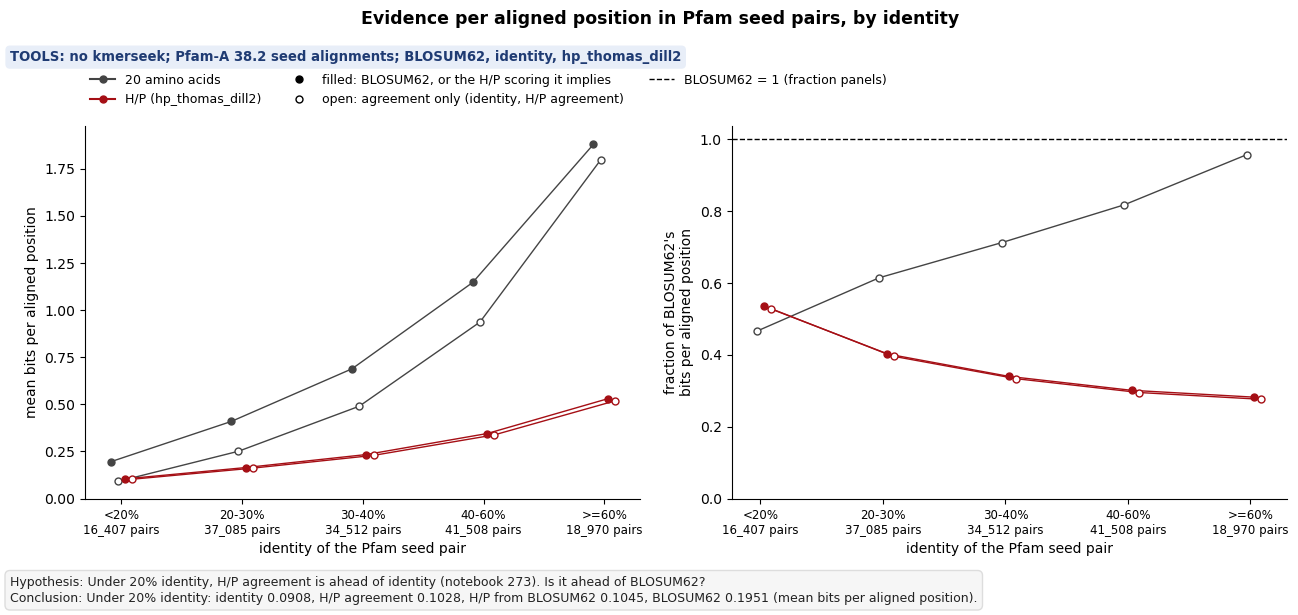

In [4]:
pf_tab = summarise(pfam, ["identity_bin"], "family")
print("Pfam seed pairs by identity: mean per pair, 95% interval resampling families")
print(pf_tab)
pf_diff = differences(pfam, ["identity_bin"], "family", "BLOSUM62")
print("\nH/P scorings minus BLOSUM62, Pfam, by identity bin")
print(pf_diff)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
plot_scorings(axes[0], pf_tab, "identity_bin")
plot_scorings(axes[1], pf_tab, "identity_bin", ratio=True)
npairs = (
    pf_tab.filter(pl.col("scheme") == "BLOSUM62")
    .sort("identity_bin")["pairs"]
    .to_list()
)
for ax in axes:
    ax.set_xticks(
        range(len(hc.IDENTITY_LABELS)),
        [f"{b}\n{n:_} pairs" for b, n in zip(hc.IDENTITY_LABELS, npairs)],
        fontsize=8.5,
    )
    ax.set_xlabel("identity of the Pfam seed pair")
axes[0].set_ylabel("mean bits per aligned position")
axes[1].set_ylabel("fraction of BLOSUM62's\nbits per aligned position")
axes[0].legend(
    handles=handles,
    loc="lower left",
    bbox_to_anchor=(0, 1.04),
    ncol=3,
    frameon=False,
    fontsize=9,
    borderaxespad=0,
).set_in_layout(False)
lo_row = pf_tab.filter(pl.col("identity_bin") == "<20%")
zb = lo_row.filter(pl.col("scheme") == "BLOSUM62")["bits per position"][0]
zi = lo_row.filter(pl.col("scheme") == "identity")["bits per position"][0]
za = lo_row.filter(pl.col("scheme") == "H/P agreement")["bits per position"][0]
zh = lo_row.filter(pl.col("scheme") == "H/P from BLOSUM62")["bits per position"][0]
hc.finish_figure(
    fig,
    FIG / "278_bits_per_position_hp_vs_blosum62_pfam_seed_by_identity.png",
    tools=f"no kmerseek; Pfam-A 38.2 seed alignments; BLOSUM62, identity, {HP}",
    title="Evidence per aligned position in Pfam seed pairs, by identity",
    hypothesis="Under 20% identity, H/P agreement is ahead of identity (notebook 273). Is it ahead of BLOSUM62?",
    conclusion=(
        f"Under 20% identity: identity {zi}, H/P agreement {za}, H/P from BLOSUM62 {zh}, BLOSUM62 {zb} "
        "(mean bits per aligned position)."
    ),
)

## 4. All 19 kmerseek alphabets against BLOSUM62

Sections 2 and 3 tested one H/P alphabet. kmerseek has 19 alphabets, from 2 to 20 letters,
listed in its `src/rust/alphabets.rs` (checked against `hp_conservation_utils.py` on
2026-10-12). Each one is scored two ways:

* **agreement**: 1 if the two residues are in the same class, else 0. This is what an exact
  k-mer match in that alphabet sees.
* **from BLOSUM62**: BLOSUM62's pair frequencies summed into that alphabet's classes, as
  log-odds in bits. For protein20 this is BLOSUM62 itself, and its agreement scoring is
  identity, so the protein20 rows check against sections 2 and 3.

The measure is the same mean bits per aligned position, on four groups of pairs: SCOPe same
family, same superfamily (different family), and same fold (different superfamily), all
identities; and Pfam seed pairs under 20% identity.

**Decision rule, written before this section was run.** An alphabet beats BLOSUM62 if either
of its scorings has higher mean bits per aligned position than BLOSUM62 in one of the three
SCOPe groups, with the 95% interval of the difference above zero (resampling query domains).
If none does, these data provide no statistically resolved lead over BLOSUM62 under this
rule. They do not establish that every alphabet has lower evidence per position.

The figure has one panel per group. Each row is an alphabet, ordered by number of letters and
grouped by size (2-3, 4-8, 12-18 letters, then protein20). The dashed line is BLOSUM62. Filled
marks are the "from BLOSUM62" scoring and open marks agreement. Dark red is `hp_thomas_dill2`,
the H/P alphabet of sections 2 and 3; pale red the other H/P alphabets; grey the rest. Further
right is better.

Mean bits per aligned position, every kmerseek alphabet; intervals resample query domains (SCOPe) or families (Pfam)
shape: (152, 11)
┌─────────────────────────────────┬──────────────────────────┬─────────┬───────────────┬───────┬───────────────────┬────────┬────────┬──────────────────────┬────────────────┬───────────────────┐
│ group                           ┆ alphabet                 ┆ letters ┆ scoring       ┆ pairs ┆ bits per position ┆ 95% lo ┆ 95% hi ┆ fraction of BLOSUM62 ┆ minus BLOSUM62 ┆ ahead of BLOSUM62 │
│ ---                             ┆ ---                      ┆ ---     ┆ ---           ┆ ---   ┆ ---               ┆ ---    ┆ ---    ┆ ---                  ┆ ---            ┆ ---               │
│ str                             ┆ str                      ┆ i64     ┆ str           ┆ i64   ┆ f64               ┆ f64    ┆ f64    ┆ f64                  ┆ f64            ┆ bool              │
╞═════════════════════════════════╪══════════════════════════╪═════════╪══════════════

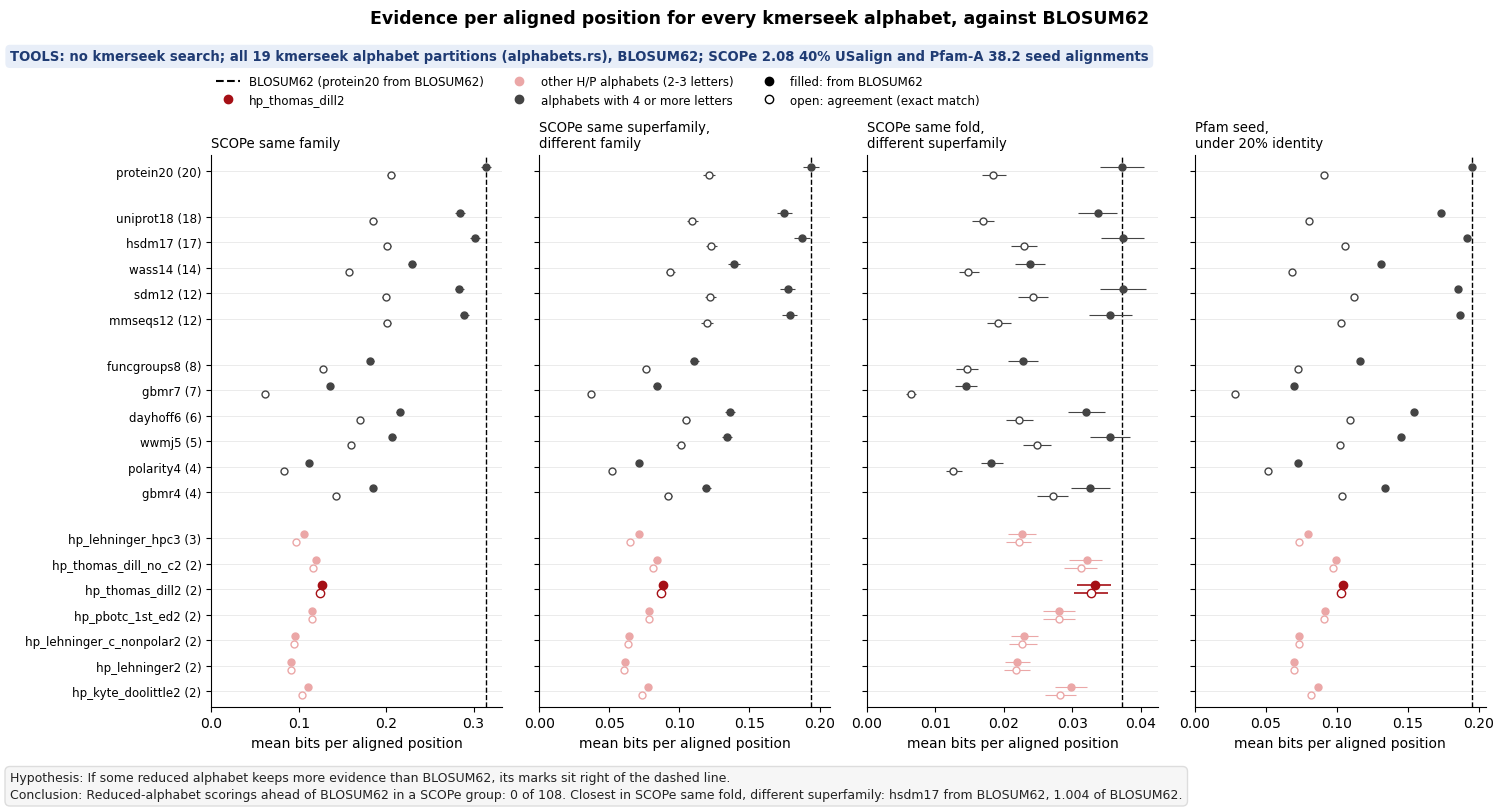

In [5]:
PFAM_ALL = Path("/Users/olga/data/pfam/278_pfam_seed_pair_scores_all_alphabets.parquet")
SCOPE_ALL = Path("/Users/olga/data/scope/278_scope40_pair_scores_all_alphabets.parquet")
ALPHABETS = sorted(hc.ALPHABET_CLUSTERS, key=lambda a: (hc.SIZES[a], a))
ALL_SCHEMES = {}
for a in ALPHABETS:
    ALL_SCHEMES[f"{a} | agreement"] = hc.agreement_bits(a)
    ALL_SCHEMES[f"{a} | from BLOSUM62"] = hc.class_bits(p62, background, a)


def load_or_compute_all(df, out_path, keys):
    if out_path.exists():
        return pl.read_parquet(out_path)
    t = hc.score_pairs(
        df["qaln"].to_list(), df["taln"].to_list(), ALL_SCHEMES, MIN_COLS
    )
    t = t.join(
        df.select(keys)
        .with_row_index("row")
        .with_columns(pl.col("row").cast(pl.Int64)),
        on="row",
    ).drop("row")
    t.write_parquet(out_path)
    return t


def split_scheme(df):
    return df.with_columns(
        pl.col("scheme").str.split(" | ").list.get(0).alias("alphabet"),
        pl.col("scheme").str.split(" | ").list.get(1).alias("scoring"),
    )


pfam_all = split_scheme(
    hc.add_identity_bin(
        load_or_compute_all(
            pfam_aln, PFAM_ALL, ["family", "query", "target", "seqid_ali"]
        )
    )
)
scope_all = split_scheme(
    hc.add_identity_bin(
        load_or_compute_all(
            scope_aln, SCOPE_ALL, ["query", "target", "category", "seqid_ali"]
        )
    )
)

GROUPS = [
    (
        "SCOPe same family",
        scope_all.filter(pl.col("category") == "same_family"),
        "query",
    ),
    (
        "SCOPe same superfamily,\ndifferent family",
        scope_all.filter(pl.col("category") == "same_superfamily_diff_family"),
        "query",
    ),
    (
        "SCOPe same fold,\ndifferent superfamily",
        scope_all.filter(pl.col("category") == "same_fold_diff_superfamily"),
        "query",
    ),
    (
        "Pfam seed,\nunder 20% identity",
        pfam_all.filter(pl.col("identity_bin") == "<20%"),
        "family",
    ),
]

rows = []
for gname, g, cluster in GROUPS:
    blosum = g.filter(pl.col("scheme") == "protein20 | from BLOSUM62").select(
        "query", "target", pl.col("bits_per_position").alias("b62")
    )
    gb = g.join(blosum, on=["query", "target"])
    for (scheme,), h in gb.group_by(["scheme"]):
        m, lo, hi = hc.cluster_bootstrap_mean_ci(
            h["bits_per_position"], h[cluster], N_BOOT, SEED
        )
        dm, dlo, dhi = hc.cluster_bootstrap_mean_ci(
            h["bits_per_position"] - h["b62"], h[cluster], N_BOOT, SEED
        )
        a, sc = scheme.split(" | ")
        rows.append(
            {
                "group": gname.replace("\n", " "),
                "alphabet": a,
                "letters": hc.SIZES[a],
                "scoring": sc,
                "pairs": h.height,
                "bits per position": round(m, 4),
                "95% lo": round(lo, 4),
                "95% hi": round(hi, 4),
                "fraction of BLOSUM62": round(m / float(h["b62"].mean()), 3),
                "minus BLOSUM62": round(dm, 4),
                "diff 95% lo": round(dlo, 4),
                "diff 95% hi": round(dhi, 4),
                "ahead of BLOSUM62": dlo > 0,
            }
        )
all_tab = pl.DataFrame(rows).sort("group", "letters", "alphabet", "scoring")
with pl.Config(tbl_rows=200):
    print(
        "Mean bits per aligned position, every kmerseek alphabet; intervals resample query domains (SCOPe) or families (Pfam)"
    )
    print(all_tab.drop("diff 95% lo", "diff 95% hi"))
scope_rule = all_tab.filter(
    pl.col("group").str.starts_with("SCOPe"), pl.col("alphabet") != "protein20"
)
print(
    f"\nDecision rule: alphabet-scorings ahead of BLOSUM62 in a SCOPe group: "
    f"{int(scope_rule['ahead of BLOSUM62'].sum())} of {scope_rule.height}"
)
best = (
    all_tab.filter(pl.col("alphabet") != "protein20")
    .sort("fraction of BLOSUM62", descending=True)
    .group_by("group", maintain_order=True)
    .head(3)
    .select(
        "group",
        "alphabet",
        "scoring",
        "bits per position",
        "fraction of BLOSUM62",
        "minus BLOSUM62",
        "diff 95% lo",
        "diff 95% hi",
    )
)
print("\nClosest three reduced alphabets to BLOSUM62 in each group")
print(best)
chk = all_tab.filter(
    pl.col("alphabet") == "protein20",
    pl.col("group") == "Pfam seed, under 20% identity",
)
print(
    "\nCheck against section 3, Pfam under 20%: protein20 agreement = identity, protein20 from BLOSUM62 = BLOSUM62"
)
print(chk.select("scoring", "bits per position"))

fig, axes = plt.subplots(1, len(GROUPS), figsize=(15, 6.6), sharey=True)
HP_RED, HP_RED_PALE, GREY = "#a50f15", "#eba7a7", "#444444"


def size_group(n):
    # Alphabet size groups, as in clear-figures rule 7d: 2-3, 4-8, 12-18 letters, then protein20.
    return 0 if n <= 3 else 1 if n <= 8 else 2 if n <= 18 else 3


ypos, y, prev = {}, 0.0, None
for a in ALPHABETS:
    g = size_group(hc.SIZES[a])
    if prev is not None and g != prev:
        y += 0.8  # gap between size groups
    ypos[a], y, prev = y, y + 1, g
for ax, (gname, _, _) in zip(axes, GROUPS):
    for yy in ypos.values():
        ax.axhline(yy, color="#e3e3e3", lw=0.5, zorder=0)  # guide line from each tick
    t = all_tab.filter(pl.col("group") == gname.replace("\n", " "))
    b62 = t.filter(
        pl.col("alphabet") == "protein20", pl.col("scoring") == "from BLOSUM62"
    )["bits per position"][0]
    ax.axvline(b62, color="black", ls="--", lw=1)
    for r in t.iter_rows(named=True):
        a = r["alphabet"]
        col = HP_RED if a == HP else HP_RED_PALE if a.startswith("hp_") else GREY
        filled = r["scoring"] == "from BLOSUM62"
        yy = ypos[a] + (0.15 if filled else -0.15)
        ax.errorbar(
            r["bits per position"],
            yy,
            xerr=[
                [r["bits per position"] - r["95% lo"]],
                [r["95% hi"] - r["bits per position"]],
            ],
            fmt="o",
            ms=6 if a == HP else 5,
            color=col,
            mfc=col if filled else "white",
            mec=col,
            ecolor=col,
            elinewidth=1.2 if a == HP else 0.8,
            capsize=0,
            zorder=4 if a == HP else 3,
        )
    ax.set_title(gname, loc="left", fontsize=9.5)
    ax.set_xlim(left=0)
    ax.set_xlabel("mean bits per aligned position")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_yticks(
    list(ypos.values()), [f"{a} ({hc.SIZES[a]})" for a in ypos], fontsize=8.5
)
axes[0].set_ylim(-0.6, y - 0.4)
leg = [
    Line2D([], [], color="black", ls="--", label="BLOSUM62 (protein20 from BLOSUM62)"),
    Line2D([], [], ls="", marker="o", color=HP_RED, label=HP),
    Line2D(
        [],
        [],
        ls="",
        marker="o",
        color=HP_RED_PALE,
        label="other H/P alphabets (2-3 letters)",
    ),
    Line2D(
        [], [], ls="", marker="o", color=GREY, label="alphabets with 4 or more letters"
    ),
    Line2D([], [], ls="", marker="o", color="black", label="filled: from BLOSUM62"),
    Line2D(
        [],
        [],
        ls="",
        marker="o",
        color="black",
        mfc="white",
        label="open: agreement (exact match)",
    ),
]
axes[0].legend(
    handles=leg,
    loc="lower left",
    bbox_to_anchor=(0, 1.08),
    ncol=3,
    frameon=False,
    fontsize=8.5,
    borderaxespad=0,
).set_in_layout(False)
n_ahead = int(scope_rule["ahead of BLOSUM62"].sum())
top = best.row(0, named=True)
hc.finish_figure(
    fig,
    FIG / "278_bits_per_position_all_kmerseek_alphabets_vs_blosum62.png",
    tools="no kmerseek search; all 19 kmerseek alphabet partitions (alphabets.rs), BLOSUM62; SCOPe 2.08 40% USalign and Pfam-A 38.2 seed alignments",
    title="Evidence per aligned position for every kmerseek alphabet, against BLOSUM62",
    hypothesis="If some reduced alphabet keeps more evidence than BLOSUM62, its marks sit right of the dashed line.",
    conclusion=(
        f"Reduced-alphabet scorings ahead of BLOSUM62 in a SCOPe group: {n_ahead} of {scope_rule.height}. "
        f"Closest in {top['group']}: {top['alphabet']} {top['scoring']}, {top['fraction of BLOSUM62']} of BLOSUM62."
    ),
)

## 5. Among exact-match alphabets, H/P leads at the fold level

**Found after looking at section 4, not tested by a rule written beforehand.** kmerseek finds
hits by exact k-mer matches, so the scoring it uses is agreement: a position counts when the
two residues fall in the same class. BLOSUM62 cannot be used for exact matching. So the
comparison that matters for a k-mer index is between alphabets, under agreement scoring.

The left panel shows each alphabet's exact-match bits per aligned position divided by
protein20's (identity), at each SCOPe level, from same family to different fold. Above the
dotted line at 1 is more evidence per position than exact matching of the 20 amino acids.
Red lines are the H/P alphabets, grey lines the others, and black is gbmr4, the best
alphabet that isn't H/P at the fold level.

The right panel checks that the fold-level result is not one kind of protein. It splits the
same fold, different superfamily pairs by SCOPe class (the query's; in every pair the target
is in the same class) and shows `hp_thomas_dill2` minus gbmr4 and minus protein20, with 95%
intervals resampling query domains. Above zero means H/P is ahead.

Two checks are printed under the figure. The first asks whether the lead is specific to pairs
that share a fold: it compares the lead in same-fold pairs with the lead in different-fold
pairs, which SCOPe calls unrelated. All of those also pass TM-score 0.5, so they are
structurally similar. The second repeats the same-fold intervals resampling whole SCOPe folds
instead of query domains.

Exact-match (agreement) bits per aligned position, every alphabet, by SCOPe level
shape: (76, 6)
┌──────────────────────────────┬──────────────────────────┬───────┬────────┬────────────────────┬────────────┐
│ category                     ┆ alphabet                 ┆ pairs ┆ bits   ┆ ratio to protein20 ┆ rank of 19 │
│ ---                          ┆ ---                      ┆ ---   ┆ ---    ┆ ---                ┆ ---        │
│ enum                         ┆ str                      ┆ u32   ┆ f64    ┆ f64                ┆ i32        │
╞══════════════════════════════╪══════════════════════════╪═══════╪════════╪════════════════════╪════════════╡
│ same_family                  ┆ protein20                ┆ 11117 ┆ 0.2053 ┆ 1.0                ┆ 1          │
│ same_family                  ┆ hsdm17                   ┆ 11117 ┆ 0.2015 ┆ 0.981              ┆ 2          │
│ same_family                  ┆ mmseqs12                 ┆ 11117 ┆ 0.2011 ┆ 0.979              ┆ 3          │
│ same_family  

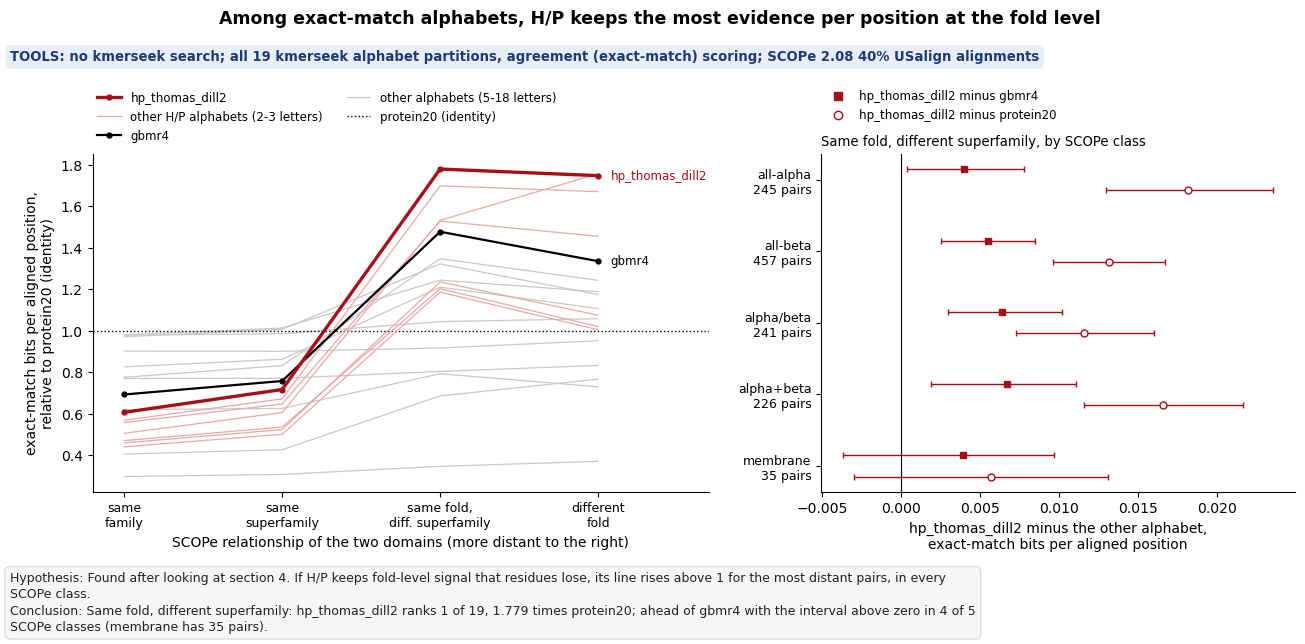

In [6]:
sccs = {}
with open(
    Path("/Users/olga/data/scope/astral-scopedom-seqres-gd-sel-gs-bib-40-2.08.fa")
) as fh:
    for line in fh:
        if line.startswith(">"):
            f = line[1:].split()
            sccs[f[0]] = f[1]
LEVELS = CAT_ORDER
LEVEL_LABEL = {
    "same_family": "same\nfamily",
    "same_superfamily_diff_family": "same\nsuperfamily",
    "same_fold_diff_superfamily": "same fold,\ndiff. superfamily",
    "diff_fold_same_class": "different\nfold",
}
agree = scope_all.filter(pl.col("scoring") == "agreement")
lvl = (
    agree.group_by("category", "alphabet")
    .agg(pl.len().alias("pairs"), pl.col("bits_per_position").mean().alias("bits"))
    .join(
        agree.filter(pl.col("alphabet") == "protein20")
        .group_by("category")
        .agg(pl.col("bits_per_position").mean().alias("p20")),
        on="category",
    )
    .with_columns((pl.col("bits") / pl.col("p20")).round(3).alias("ratio to protein20"))
    .with_columns(
        pl.col("bits")
        .rank(descending=True)
        .over("category")
        .cast(pl.Int32)
        .alias("rank of 19")
    )
    .with_columns(pl.col("category").cast(pl.Enum(LEVELS)))
    .sort("category", "rank of 19")
)
with pl.Config(tbl_rows=100):
    print(
        "Exact-match (agreement) bits per aligned position, every alphabet, by SCOPe level"
    )
    print(lvl.with_columns(pl.col("bits").round(4)).drop("p20"))

wf = agree.filter(pl.col("category") == "same_fold_diff_superfamily").pivot(
    on="alphabet", index=["query", "target"], values="bits_per_position"
)
wf = wf.with_columns(
    pl.col("query").replace_strict(sccs, default="?").str.slice(0, 1).alias("class"),
    pl.col("target")
    .replace_strict(sccs, default="?")
    .str.slice(0, 1)
    .alias("target_class"),
)
orows = []
for cat in [
    "same_superfamily_diff_family",
    "same_fold_diff_superfamily",
    "diff_fold_same_class",
]:
    g = agree.filter(pl.col("category") == cat).pivot(
        on="alphabet", index=["query", "target"], values="bits_per_position"
    )
    for other in ["gbmr4", "protein20"]:
        m, lo, hi = hc.cluster_bootstrap_mean_ci(
            g[HP] - g[other], g["query"], N_BOOT, SEED
        )
        orows.append(
            {
                "SCOPe level": cat,
                "pairs": g.height,
                "comparison": f"{HP} minus {other}",
                "difference": round(m, 4),
                "95% lo": round(lo, 4),
                "95% hi": round(hi, 4),
            }
        )
print(
    "\nAll classes together: exact-match bits per aligned position, 95% interval resampling query domains"
)
print(pl.DataFrame(orows))

# Is the lead specific to pairs that share a fold? Compare with different-fold pairs, which SCOPe
# calls unrelated (all pass TM-score >= 0.5, so they are structurally similar).
by_cat = {
    cat: agree.filter(pl.col("category") == cat).pivot(
        on="alphabet", index=["query", "target"], values="bits_per_position"
    )
    for cat in ["same_fold_diff_superfamily", "diff_fold_same_class"]
}
sf_w, df_w = by_cat["same_fold_diff_superfamily"], by_cat["diff_fold_same_class"]
drows = []
for other in ["gbmr4", "protein20"]:
    m, lo, hi = hc.cluster_bootstrap_diff_of_means(
        sf_w[HP] - sf_w[other],
        sf_w["query"],
        df_w[HP] - df_w[other],
        df_w["query"],
        N_BOOT,
        SEED,
    )
    drows.append(
        {
            "comparison": f"{HP} minus {other}",
            "same fold": round(float((sf_w[HP] - sf_w[other]).mean()), 4),
            "different fold": round(float((df_w[HP] - df_w[other]).mean()), 4),
            "same minus different": round(m, 4),
            "95% lo": round(lo, 4),
            "95% hi": round(hi, 4),
        }
    )
print(
    f"\nIs the lead larger when the pair shares a fold? Same fold ({sf_w.height:_} pairs) minus different fold ({df_w.height:_} pairs); each group resampled by query domain"
)
print(pl.DataFrame(drows))

# The same-fold intervals again, resampling whole SCOPe folds of the query instead of query domains.
sf_w = sf_w.with_columns(
    pl.col("query")
    .replace_strict(sccs, default="?")
    .str.split(".")
    .list.slice(0, 2)
    .list.join(".")
    .alias("fold")
)
fold_sizes = sf_w.group_by("fold").len().sort("len", descending=True)
frows = []
for other in ["gbmr4", "protein20"]:
    m, lo, hi = hc.cluster_bootstrap_mean_ci(
        sf_w[HP] - sf_w[other], sf_w["fold"], N_BOOT, SEED
    )
    frows.append(
        {
            "comparison": f"{HP} minus {other}",
            "difference": round(m, 4),
            "95% lo, resampling folds": round(lo, 4),
            "95% hi, resampling folds": round(hi, 4),
        }
    )
print(
    f"\nSame fold, different superfamily: {sf_w.height:_} pairs from {fold_sizes.height} folds; the five largest folds hold {fold_sizes['len'].head(5).sum() / sf_w.height:.0%} of the pairs"
)
print(pl.DataFrame(frows))
CLASS_NAME = {
    "a": "all-alpha",
    "b": "all-beta",
    "c": "alpha/beta",
    "d": "alpha+beta",
    "f": "membrane",
}
print(
    f"\nSame fold, different superfamily: {wf.height:_} pairs; query and target in the same SCOPe class: {(wf['class'] == wf['target_class']).mean():.0%}"
)
crows = []
for c in ["a", "b", "c", "d", "f"]:
    g = wf.filter(pl.col("class") == c)
    means = {a: g[a].mean() for a in hc.ALPHABET_CLUSTERS}
    order = sorted(means, key=means.get, reverse=True)
    for other in ["gbmr4", "protein20"]:
        m, lo, hi = hc.cluster_bootstrap_mean_ci(
            g[HP] - g[other], g["query"], N_BOOT, SEED
        )
        crows.append(
            {
                "class": CLASS_NAME[c],
                "pairs": g.height,
                f"{HP} rank of 19": order.index(HP) + 1,
                "comparison": f"{HP} minus {other}",
                "difference": round(m, 4),
                "95% lo": round(lo, 4),
                "95% hi": round(hi, 4),
            }
        )
class_tab = pl.DataFrame(crows)
print(class_tab)

HP_RED, HP_RED_PALE = "#a50f15", "#eba7a7"
fig, (ax, ax2) = plt.subplots(
    1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]}
)
xl = np.arange(len(LEVELS))
for a in hc.ALPHABET_CLUSTERS:
    if a == "protein20":
        continue
    t = lvl.filter(pl.col("alphabet") == a).sort("category")
    # hp_thomas_dill2 is the only full-strength red and is drawn on top; the other H/P
    # alphabets are a pale tint of the same red with no dots, so it stands apart from them.
    if a == HP:
        col, lw, z, mk = HP_RED, 2.4, 5, "o"
    elif a.startswith("hp_"):
        col, lw, z, mk = HP_RED_PALE, 0.9, 3, None
    elif a == "gbmr4":
        col, lw, z, mk = "black", 1.6, 4, "o"
    else:
        col, lw, z, mk = "#c8c8c8", 0.9, 1, None
    ax.plot(
        xl,
        t["ratio to protein20"].to_numpy(),
        color=col,
        lw=lw,
        zorder=z,
        marker=mk,
        ms=3.5,
    )
    if a in (HP, "gbmr4"):
        ax.text(
            xl[-1] + 0.08,
            t["ratio to protein20"][-1],
            a,
            va="center",
            fontsize=8.5,
            color=col,
        )
ax.axhline(1, color="black", ls=":", lw=1)
ax.set_xticks(xl, [LEVEL_LABEL[c] for c in LEVELS], fontsize=9)
ax.set_xlim(-0.2, len(LEVELS) - 0.3)
ax.set_ylabel(
    "exact-match bits per aligned position,\nrelative to protein20 (identity)"
)
ax.set_xlabel("SCOPe relationship of the two domains (more distant to the right)")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(
    handles=[
        Line2D([], [], color=HP_RED, lw=2.4, marker="o", ms=3.5, label=f"{HP}"),
        Line2D(
            [], [], color=HP_RED_PALE, lw=0.9, label="other H/P alphabets (2-3 letters)"
        ),
        Line2D([], [], color="black", lw=1.6, marker="o", ms=3.5, label="gbmr4"),
        Line2D([], [], color="#c8c8c8", lw=0.9, label="other alphabets (5-18 letters)"),
        Line2D([], [], color="black", ls=":", lw=1, label="protein20 (identity)"),
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.02),
    ncol=2,
    frameon=False,
    fontsize=8.5,
    borderaxespad=0,
)
classes = [CLASS_NAME[c] for c in ["a", "b", "c", "d", "f"]]
yc = np.arange(len(classes))
# Both comparisons are hp_thomas_dill2's lead, so both use its red; the marker shape says
# which alphabet it is compared with.
for j, (other, col, mk) in enumerate(
    [("gbmr4", HP_RED, "s"), ("protein20", HP_RED, "o")]
):
    t = class_tab.filter(pl.col("comparison") == f"{HP} minus {other}")
    m = t["difference"].to_numpy()
    ax2.errorbar(
        m,
        yc + (j - 0.5) * 0.3,
        xerr=[m - t["95% lo"].to_numpy(), t["95% hi"].to_numpy() - m],
        fmt=mk,
        color=col,
        mfc="white" if other == "protein20" else col,
        ms=5,
        capsize=2,
        lw=1,
    )
ax2.axvline(0, color="black", lw=0.8)
npc = class_tab.filter(pl.col("comparison") == f"{HP} minus gbmr4")["pairs"].to_list()
ax2.set_yticks(yc, [f"{c}\n{n:_} pairs" for c, n in zip(classes, npc)], fontsize=9)
ax2.invert_yaxis()
ax2.set_xlabel(f"{HP} minus the other alphabet,\nexact-match bits per aligned position")
ax2.set_title(
    "Same fold, different superfamily, by SCOPe class", loc="left", fontsize=9.5
)
for side in ("top", "right"):
    ax2.spines[side].set_visible(False)
ax2.legend(
    handles=[
        Line2D([], [], ls="", marker="s", color=HP_RED, label=f"{HP} minus gbmr4"),
        Line2D(
            [],
            [],
            ls="",
            marker="o",
            color=HP_RED,
            mfc="white",
            label=f"{HP} minus protein20",
        ),
    ],
    loc="lower left",
    bbox_to_anchor=(0, 1.08),
    ncol=1,
    frameon=False,
    fontsize=8.5,
    borderaxespad=0,
)
fold = lvl.filter(pl.col("category") == "same_fold_diff_superfamily")
td = fold.filter(pl.col("alphabet") == HP).row(0, named=True)
n_lead = int(
    (class_tab.filter(pl.col("comparison") == f"{HP} minus gbmr4")["95% lo"] > 0).sum()
)
hc.finish_figure(
    fig,
    FIG / "278_exact_match_bits_hp_leads_at_fold_level.png",
    tools=f"no kmerseek search; all 19 kmerseek alphabet partitions, agreement (exact-match) scoring; SCOPe 2.08 40% USalign alignments",
    title="Among exact-match alphabets, H/P keeps the most evidence per position at the fold level",
    hypothesis=(
        "Found after looking at section 4. If H/P keeps fold-level signal that residues lose, its line rises above 1 "
        "for the most distant pairs, in every SCOPe class."
    ),
    conclusion=(
        f"Same fold, different superfamily: {HP} ranks {td['rank of 19']} of 19, {td['ratio to protein20']} times protein20; "
        f"ahead of gbmr4 with the interval above zero in {n_lead} of 5 SCOPe classes (membrane has 35 pairs)."
    ),
)

## 6. Summary and conclusions

**Question.** Notebook 273 found H/P giving 1.13 times the evidence per aligned position of
the 20 amino acids in Pfam pairs under 20% identity, with the 20 amino acids scored by
identity. Does H/P still give more when the 20 amino acids are scored with BLOSUM62? And does
any kmerseek alphabet?

**Answer.** No alphabet has a lead over BLOSUM62 whose 95% difference interval is above zero. But BLOSUM62
cannot be used for exact k-mer matching, and among exact-match scorings H/P is the best of all
19 kmerseek alphabets for the most distant pairs, the SCOPe fold level. That second result was
found after looking, not tested by a rule written beforehand.

1. Pfam pairs under 20% identity, the bin where notebook 273 found the H/P lead (16,407
   pairs): identity 0.0908 bits per aligned position, H/P agreement 0.1028 (the 1.13 times),
   H/P from BLOSUM62 0.1045, BLOSUM62 0.1951. BLOSUM62 gives 1.90 times what H/P agreement
   gives. A pair at those means needs about 103 aligned positions with BLOSUM62 and 195 with
   H/P agreement before an unrelated pair has a one-in-a-million chance of scoring as well.
2. SCOPe, same superfamily but a different family, all identities (11,998 pairs): BLOSUM62
   0.1936 bits, H/P from BLOSUM62 0.0884, H/P agreement 0.0869. Same family: 0.3143 against
   0.1271 and 0.1247. Same fold, different superfamily (1,204 pairs): BLOSUM62 0.0373, H/P
   from BLOSUM62 0.0333 (difference -0.0040, 95% interval -0.0061 to -0.0020). BLOSUM45 gives
   the same verdict.
3. All 19 kmerseek alphabets, each scored by agreement and by its classes' BLOSUM62 log-odds,
   in three SCOPe groups: 0 of 108 scorings are ahead of BLOSUM62 (section 4). The closest
   are hsdm17 and sdm12 from BLOSUM62 at the fold level, 1.004 and 1.003 of BLOSUM62, a tie.
4. Exact-match (agreement) scoring is what a k-mer index uses. Ranked by it, protein20 is
   first at the family level, and H/P alphabets sit near the bottom. As the pairs get more
   distant, H/P moves up. At the fold level (same fold, different superfamily),
   `hp_thomas_dill2` ranks first of 19, with 1.78 times protein20's exact-match evidence per
   position, and the top four alphabets are all H/P (section 5). It is ahead of gbmr4, the
   best alphabet that isn't H/P, by 0.0056 bits (95% interval 0.0036 to 0.0074; 0.0035 to
   0.0076 resampling the 112 folds instead of query domains).
5. `hp_thomas_dill2` ranks first of 19 in all five SCOPe classes of fold-level pairs. Its lead
   over gbmr4 has an interval above zero in all-alpha, all-beta, alpha/beta and alpha+beta.
   The membrane group has 35 pairs, and both of its intervals span zero.
6. The lead over gbmr4 is not specific to sharing a fold. In different-fold pairs (186),
   which SCOPe calls unrelated but which all pass TM-score 0.5, `hp_thomas_dill2` is ahead of
   gbmr4 by 0.0048 bits, against 0.0056 in same-fold pairs: a difference of 0.0008 (95%
   interval -0.0026 to 0.0043). The lead over protein20 is larger in same-fold pairs: 0.0143
   against 0.0086, a difference of 0.0057 (0.0018 to 0.0099).
7. How H/P positions are scored barely matters. In every SCOPe category and in the Pfam bins
   under 30% identity, H/P from BLOSUM62 is at most 0.003 bits above plain H/P agreement
   (0.011 at 60% identity and above), against gaps of 0.001 to 1.36 bits to BLOSUM62.
8. The z per position measure agrees on BLOSUM62 (ahead in all 8 comparisons of section 2).
   It differs from bits on identity against H/P agreement: under 20% identity it ranks
   identity higher (0.408 against 0.355), the opposite of notebook 273. z assumes chance
   scores are spread like a bell curve, which is far off when chance agreement is as low as
   identity's (about 6.5 per 100 under 20% identity, notebook 273), so bits decide.

**Limits.**
* Aligned positions only, with the alignment given (Pfam seed, or USalign for SCOPe). Bits per
  aligned position is not the same as sharing a long exact k-mer: notebook 230 found H/P
  26-mers shared by 1.7% of 20-30% Pfam pairs. Whether the fold-level lead turns into more
  fold-level hits needs a kmerseek search (the SCOPe40 sweep in PR 107 has the hits).
* Same fold, different superfamily pairs share a fold, but SCOPe does not say they share an
  ancestor. The H/P lead there may be shared packing rather than descent. Different-fold
  pairs show the same lead over gbmr4 (item 6; notebook 230 made the same point). There are
  only 186 of them, so this shows no evidence of a fold-specific lead over gbmr4, not that
  none exists.
* Section 5 was found by looking at section 4. The per-class split is a check on the same
  pairs, not new data.
* The residue background is the Pfam seed composition, also used for the SCOPe pairs. The
  BLOSUM62 scale factor it gives, 0.4595 bits per score unit, is within 0.3% of the published
  0.3176 nats (0.458 bits).
* The rule for sections 2 and 3 was written after a pilot on the same data and after
  switching from z to bits; both measures give the same BLOSUM62 verdict.
* SCOPe intervals resample query domains. For the fold-level lead, resampling whole folds
  instead gives nearly the same intervals (item 4).

**Decision.**
1. Notebook 273's 1.13 is not a headline: it holds only against identity scoring. Do not
   write that H/P keeps more evidence per position than the amino acids.
2. The angle for H/P is exact matching of structurally similar pairs. Among the 19 alphabets a
   k-mer index can use, `hp_thomas_dill2` keeps the most exact-match evidence per aligned
   position for pairs that share only a fold, in four of five SCOPe classes (membrane, 35
   pairs, is unresolved). Against protein20 that lead is larger when the pair shares a fold
   (item 6), which fits the paper's story of a structure-free domain finder: H/P sequence
   carries fold-level signal that exact residue matches lose. Against gbmr4 it is the same in
   different-fold pairs, which SCOPe calls unrelated, so it is not evidence of shared
   ancestry.
3. Before it goes in the paper, test it on hits, and count different-fold hits as well as
   same-fold ones. In the SCOPe40 benchmark, same-fold pairs are either left out (the
   superfamily-level measure) or counted as true positives (FoldSeek's fold-level measure),
   and different-fold pairs are false positives in both. A lead that is equally present in
   different-fold pairs adds false positives as fast as fold-level true positives. Run it on the SCOPe40 kmerseek sweep (PR 107) and
   on a second structure set.